# Jalon C — Multi-cibles maritime : GNN + clutter + IMM + OSPA

Le pistage ne travaille pas sur le signal mais sur des **détections** `(r, θ)`. On simule donc directement
10 navires dans une zone de 20 km × 20 km, avec Pd = 0,9 et ~10 fausses alarmes par balayage (loi de Poisson).

Chaîne de pistage (tout codé à la main dans `src/tracking/`) : prédiction → **gating de Mahalanobis** →
**association hongroise (GNN)** → mise à jour → confirmation M/N (3 sur 4) → suppression (5 ratés consécutifs).

Trois pisteurs, mêmes réglages sauf le filtre de chaque piste :

- **EKF-CV** : un seul modèle à vitesse constante ;
- **IMM (CV + CT)** : 2 modèles, le virage ne couvre que le sens +ω (taux 0,02 rad/s) ;
- **IMM (CV + CT±)** : 3 modèles, virages dans les deux sens (±0,02 rad/s).

Pourquoi deux IMM ? Un modèle CT a un taux de virage **signé**. Avec un seul modèle CT, l'IMM ne sait
suivre que les virages d'un sens ; on le vérifie plus bas.

In [1]:
import tempfile
import time
from concurrent.futures import ProcessPoolExecutor
from dataclasses import dataclass, replace
from multiprocessing import get_context
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import t as student_t

from metrics.ospa import ospa_over_time
from metrics.rmse import track_statistics
from sim.scenario import ScenarioParams, generate_scenario, load_scenario, save_scenario
from tracking.imm import make_imm_factory
from tracking.track_manager import TrackManager, make_ekf_factory, run_tracking

# --- style des figures : encre et surfaces neutres, palette catégorielle validée (slots 1 à 3)
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.grid": True, "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 1.8, "lines.solid_capstyle": "round", "font.family": "sans-serif",
    "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 160,
})
FIG_DIR = "../figures"

## Paramètres

`σ_a = 0,05 m/s²` est l'accélération aléatoire de la vérité **et** le bruit de modèle de tous les filtres.
Les taux de virage de la vérité sont tirés dans [0,015 ; 0,03] rad/s (signe aléatoire) : les modèles CT de
l'IMM (0,02 rad/s) sont donc **approximatifs**, pas exacts.

**OSPA** : c = 300 m, p = 2. `c` ≈ taille de la porte d'association (au-delà, une piste ne peut plus être la bonne :
elle compte comme une cible manquée plus une fausse piste) ; `p = 2` pénalise les grosses erreurs comme un RMSE.

In [2]:
N_MC = 50
SIGMA_A, OMEGA = 0.05, 0.02
OSPA_C, OSPA_P, MAX_DIST = 300.0, 2.0, 300.0

SCENARIOS = {
    "manœuvres": ScenarioParams(n_ships=10, turn_fraction=1.0),     # tous les navires font un virage
    "ligne droite": ScenarioParams(n_ships=10, turn_fraction=0.0),  # témoin : aucun virage
}


def trackers(p):
    # Les trois pisteurs : mêmes règles de gestion, seul le filtre de chaque piste change.
    args = (p.dt, SIGMA_A, p.sigma_r, p.sigma_theta)
    return {
        "EKF-CV": make_ekf_factory(*args),
        "IMM (CV + CT)": make_imm_factory(*args, turn_rates=(OMEGA,)),
        "IMM (CV + CT±)": make_imm_factory(*args, turn_rates=(OMEGA, -OMEGA)),
    }
NAMES = list(trackers(ScenarioParams()))

# Un scénario sérialisé puis relu est identique : tous les pisteurs rejouent exactement les mêmes détections.
scenario = generate_scenario(SCENARIOS["manœuvres"])
with tempfile.TemporaryDirectory() as tmp:
    save_scenario(scenario, Path(tmp) / "manoeuvres.npz")
    replayed = load_scenario(Path(tmp) / "manoeuvres.npz")
assert all(np.array_equal(a, b) for a, b in zip(replayed.detections, scenario.detections))
assert np.array_equal(replayed.truth, scenario.truth)
print(f"{scenario.params.n_ships} navires, {scenario.params.n_steps} balayages, "
      f"{sum(len(z) for z in scenario.detections)} détections dont "
      f"{sum(int((s < 0).sum()) for s in scenario.sources)} fausses alarmes ; relecture identique : OK")

10 navires, 150 balayages, 2866 détections dont 1529 fausses alarmes ; relecture identique : OK


## Expérience : 50 Monte-Carlo

Chaque tirage = un scénario différent (graine différente : trajectoires, détections, fausses alarmes) rejoué
à l'identique par les trois pisteurs. Les statistiques sont calculées en parallèle ; le **temps par mise à jour**
est mesuré à part, en séquentiel, pour ne pas être faussé par la concurrence entre processus.

In [3]:
def evaluate(args):
    # Un tirage : un scénario, les trois pisteurs, toutes les métriques (exécuté dans un processus fils).
    params, seed = args
    sc = generate_scenario(replace(params, seed=seed))
    truth_xy = [sc.truth[:, k, :2] for k in range(sc.params.n_steps)]
    out = {}
    for name, factory in trackers(sc.params).items():
        run = run_tracking(TrackManager(factory), sc.detections)
        stats = track_statistics(sc.truth, run.ids, run.states, MAX_DIST, sc.in_turn)
        pos = track_statistics(sc.truth, run.ids, run.states, MAX_DIST, sc.in_turn & (sc.turn_rate > 0)[:, None])
        neg = track_statistics(sc.truth, run.ids, run.states, MAX_DIST, sc.in_turn & (sc.turn_rate < 0)[:, None])
        ospa = ospa_over_time(truth_xy, [s[:, :2] for s in run.states], OSPA_C, OSPA_P)
        out[name] = dict(
            ospa=ospa.mean(), ospa_series=ospa, rmse=stats.rmse, rmse_turn=stats.rmse_masked,
            rmse_turn_pos=pos.rmse_masked, rmse_turn_neg=neg.rmse_masked, losses=stats.n_losses,
            id_switches=stats.n_id_switches, false_tracks=stats.n_false_tracks,
            never_tracked=stats.n_never_tracked, tracked_fraction=stats.tracked_fraction,
        )
    return out


def monte_carlo(params, n_runs=N_MC):
    with ProcessPoolExecutor(max_workers=6, mp_context=get_context("fork")) as pool:
        return list(pool.map(evaluate, [(params, seed) for seed in range(n_runs)]))


start = time.perf_counter()
results = {label: monte_carlo(params) for label, params in SCENARIOS.items()}
print(f"{2 * N_MC} scénarios × 3 pisteurs en {time.perf_counter() - start:.0f} s")

100 scénarios × 3 pisteurs en 533 s


In [4]:
def mean_ci(values, level=0.95):
    # Moyenne et demi-largeur de l'intervalle de confiance de Student (NaN ignorés).
    v = np.asarray(values, dtype=float)
    v = v[~np.isnan(v)]
    if len(v) < 2:
        return float("nan"), float("nan")
    half = student_t.ppf(0.5 + level / 2, len(v) - 1) * v.std(ddof=1) / np.sqrt(len(v))
    return v.mean(), half


COLUMNS = [
    ("OSPA moyen [m]", "ospa", "{:.1f} ± {:.1f}"),
    ("RMSE [m]", "rmse", "{:.1f} ± {:.1f}"),
    ("RMSE en virage [m]", "rmse_turn", "{:.1f} ± {:.1f}"),
    ("pertes de piste", "losses", "{:.2f} ± {:.2f}"),
    ("changements d'identité", "id_switches", "{:.1f} ± {:.1f}"),
    ("fausses pistes", "false_tracks", "{:.2f} ± {:.2f}"),
]


def table(label):
    # Tableau Markdown « moyenne ± IC à 95 % » sur les N_MC tirages d'un scénario.
    lines = ["| pisteur | " + " | ".join(c[0] for c in COLUMNS) + " |", "|---|" + "---|" * len(COLUMNS)]
    for name in NAMES:
        cells = []
        for _, key, fmt in COLUMNS:
            m, h = mean_ci([r[name][key] for r in results[label]])
            cells.append("—" if np.isnan(m) else fmt.format(m, h))  # « — » : métrique sans objet (pas de virage)
        lines.append(f"| {name} | " + " | ".join(cells) + " |")
    return "\n".join(lines)


for label in SCENARIOS:
    print(f"Scénario « {label} » ({N_MC} Monte-Carlo, moyenne ± IC à 95 %)\n")
    print(table(label), "\n")

Scénario « manœuvres » (50 Monte-Carlo, moyenne ± IC à 95 %)

| pisteur | OSPA moyen [m] | RMSE [m] | RMSE en virage [m] | pertes de piste | changements d'identité | fausses pistes |
|---|---|---|---|---|---|---|
| EKF-CV | 57.7 ± 1.8 | 45.3 ± 1.7 | 61.7 ± 2.4 | 0.30 ± 0.14 | 11.1 ± 0.7 | 0.56 ± 0.19 |
| IMM (CV + CT) | 49.0 ± 2.0 | 38.8 ± 1.7 | 48.1 ± 2.5 | 0.14 ± 0.10 | 5.6 ± 0.7 | 0.62 ± 0.19 |
| IMM (CV + CT±) | 38.8 ± 1.5 | 31.4 ± 0.9 | 32.9 ± 1.4 | 0.06 ± 0.07 | 1.3 ± 0.6 | 0.50 ± 0.18 | 

Scénario « ligne droite » (50 Monte-Carlo, moyenne ± IC à 95 %)

| pisteur | OSPA moyen [m] | RMSE [m] | RMSE en virage [m] | pertes de piste | changements d'identité | fausses pistes |
|---|---|---|---|---|---|---|
| EKF-CV | 33.8 ± 1.5 | 27.7 ± 0.7 | — | 0.00 ± 0.00 | 0.4 ± 0.2 | 0.62 ± 0.24 |
| IMM (CV + CT) | 36.3 ± 1.8 | 29.4 ± 0.7 | — | 0.04 ± 0.06 | 0.7 ± 0.4 | 0.58 ± 0.21 |
| IMM (CV + CT±) | 36.2 ± 1.6 | 29.3 ± 0.7 | — | 0.04 ± 0.06 | 0.7 ± 0.3 | 0.58 ± 0.22 | 



### Garde-fou : l'IMM gagne-t-il nettement en virage ?

Critère fixé avant l'expérience : l'IMM doit gagner nettement en virage, sinon il y a un bug. Vérification **par sens de virage**,
car l'IMM à 2 modèles ne connaît qu'un sens.

In [5]:
def turn_rmse(name, key, label="manœuvres"):
    return mean_ci([r[name][key] for r in results[label]])[0]

print(f"{'RMSE en virage [m]':26s} {'virage +ω':>10s} {'virage −ω':>10s}")
for name in NAMES:
    print(f"{name:26s} {turn_rmse(name, 'rmse_turn_pos'):10.1f} {turn_rmse(name, 'rmse_turn_neg'):10.1f}")

cv = {k: turn_rmse("EKF-CV", k) for k in ("rmse_turn", "rmse_turn_pos", "rmse_turn_neg")}
imm3 = {k: turn_rmse("IMM (CV + CT±)", k) for k in cv}
imm2 = {k: turn_rmse("IMM (CV + CT)", k) for k in cv}
# l'IMM à 3 modèles gagne nettement dans les deux sens ; celui à 2 modèles dans le sens qu'il connaît
assert imm3["rmse_turn"] < 0.7 * cv["rmse_turn"], "l'IMM CV+CT± ne gagne pas nettement en virage : chercher le bug"
assert imm3["rmse_turn_neg"] < 0.7 * cv["rmse_turn_neg"] and imm3["rmse_turn_pos"] < 0.7 * cv["rmse_turn_pos"]
assert imm2["rmse_turn_pos"] < 0.7 * cv["rmse_turn_pos"], "l'IMM CV+CT ne gagne pas dans son propre sens : chercher le bug"
print(f"\nIMM CV+CT± : {imm3['rmse_turn'] / cv['rmse_turn']:.2f} × l'erreur de l'EKF-CV en virage ; "
      f"IMM CV+CT dans son sens (+ω) : {imm2['rmse_turn_pos'] / cv['rmse_turn_pos']:.2f} ×, dans l'autre : "
      f"{imm2['rmse_turn_neg'] / cv['rmse_turn_neg']:.2f} ×")

RMSE en virage [m]          virage +ω  virage −ω
EKF-CV                           60.9       62.3
IMM (CV + CT)                    31.0       62.1
IMM (CV + CT±)                   31.8       33.3

IMM CV+CT± : 0.53 × l'erreur de l'EKF-CV en virage ; IMM CV+CT dans son sens (+ω) : 0.51 ×, dans l'autre : 1.00 ×


## Figure 1 — Un scénario et les pistes de l'IMM

Navires (vérité, gris), détections d'un balayage sur dix (points : vrais échos et fausses alarmes mélangés,
comme les voit le pisteur) et pistes confirmées de l'IMM à 3 modèles (bleu).

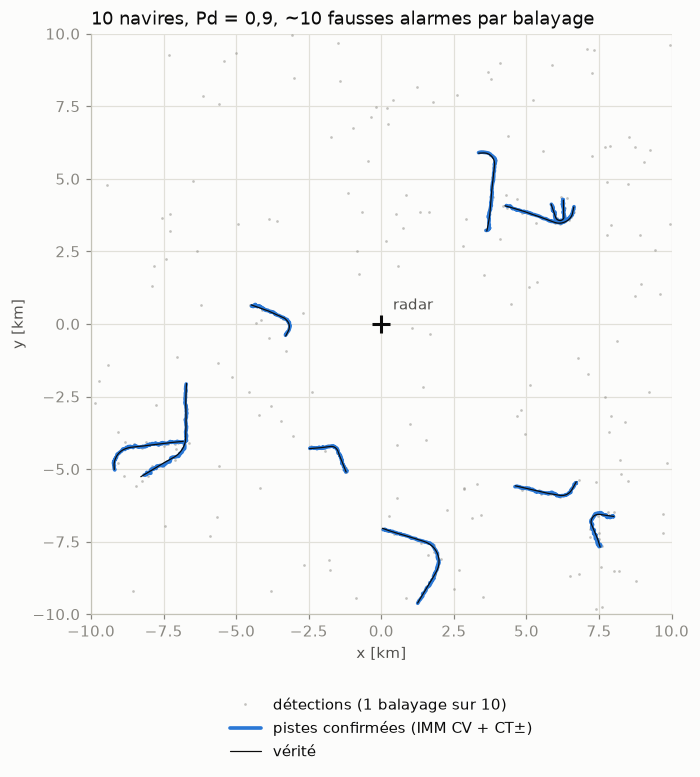

In [6]:
sc = generate_scenario(replace(SCENARIOS["manœuvres"], seed=3))
run = run_tracking(TrackManager(trackers(sc.params)["IMM (CV + CT±)"]), sc.detections)
paths = {}
for ids, states in zip(run.ids, run.states):
    for track_id, state in zip(ids, states):
        paths.setdefault(int(track_id), []).append(state[:2])

fig, ax = plt.subplots(figsize=(7.2, 7.2))
dets = np.vstack(sc.detections[::10])
ax.plot(dets[:, 0] * np.cos(dets[:, 1]) / 1e3, dets[:, 0] * np.sin(dets[:, 1]) / 1e3, ".", ms=3.5,
        color=MUTED, alpha=0.5, mew=0, label="détections (1 balayage sur 10)")
for i, (track_id, path) in enumerate(paths.items()):
    path = np.array(path) / 1e3
    ax.plot(path[:, 0], path[:, 1], color=BLUE, lw=2.4, label="pistes confirmées (IMM CV + CT±)" if i == 0 else None)
for s in range(sc.params.n_ships):  # vérité par-dessus, fine, pour voir l'écart avec les pistes
    ax.plot(sc.truth[s, :, 0] / 1e3, sc.truth[s, :, 1] / 1e3, color=INK, lw=0.8,
            label="vérité" if s == 0 else None)
ax.plot(0, 0, "+", ms=12, mew=2, color=INK)
ax.annotate("radar", (0, 0), (0.4, 0.5), color=INK2)
half = sc.params.half_size / 1e3
ax.set_xlim(-half, half)
ax.set_ylim(-half, half)
ax.set_aspect("equal")
ax.set_xlabel("x [km]")
ax.set_ylabel("y [km]")
ax.set_title("10 navires, Pd = 0,9, ~10 fausses alarmes par balayage", loc="left", color=INK)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=1)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/C_scenario.png", bbox_inches="tight")
plt.show()

## Figure 2 — OSPA au cours du temps (scénario « manœuvres »)

Moyenne sur 50 tirages et intervalle de confiance à 95 % (bande). Au début, le temps de confirmation M/N
(3 balayages) fait monter l'OSPA vers c ; ensuite l'écart entre pisteurs se creuse avec les virages.

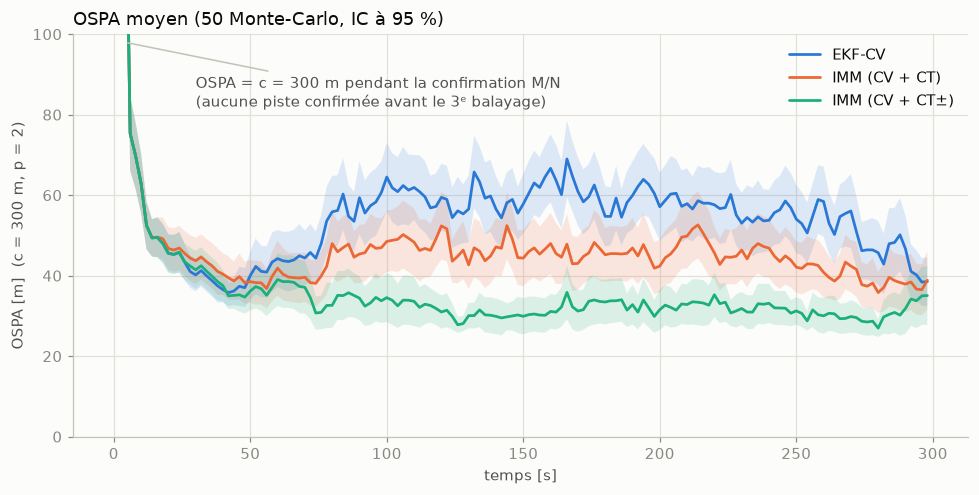

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.6))
t_axis = SCENARIOS["manœuvres"].dt * np.arange(SCENARIOS["manœuvres"].n_steps)
for name, color in zip(NAMES, [BLUE, ORANGE, AQUA]):
    series = np.array([r[name]["ospa_series"] for r in results["manœuvres"]])
    mean = series.mean(axis=0)
    half = student_t.ppf(0.975, len(series) - 1) * series.std(axis=0, ddof=1) / np.sqrt(len(series))
    ax.fill_between(t_axis, mean - half, mean + half, color=color, alpha=0.15, lw=0)
    ax.plot(t_axis, mean, color=color, label=name)
ax.set_xlabel("temps [s]")
ax.set_ylabel(f"OSPA [m]  (c = {OSPA_C:.0f} m, p = {OSPA_P:.0f})")
ax.set_ylim(0, 100)
ax.annotate("OSPA = c = 300 m pendant la confirmation M/N\n(aucune piste confirmée avant le 3ᵉ balayage)",
            xy=(4, 98), xytext=(30, 82), color=INK2, arrowprops=dict(arrowstyle="-", color=AXIS))
ax.set_title("OSPA moyen (50 Monte-Carlo, IC à 95 %)", loc="left", color=INK)
ax.legend(loc="upper right")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/C_ospa.png")
plt.show()

## Figure 3 — Erreur en virage selon le sens du virage

L'IMM à 2 modèles ne connaît que le virage +ω : il divise l'erreur par ≈ 2 dans ce sens et n'apporte rien dans l'autre.
L'IMM à 3 modèles couvre les deux sens.

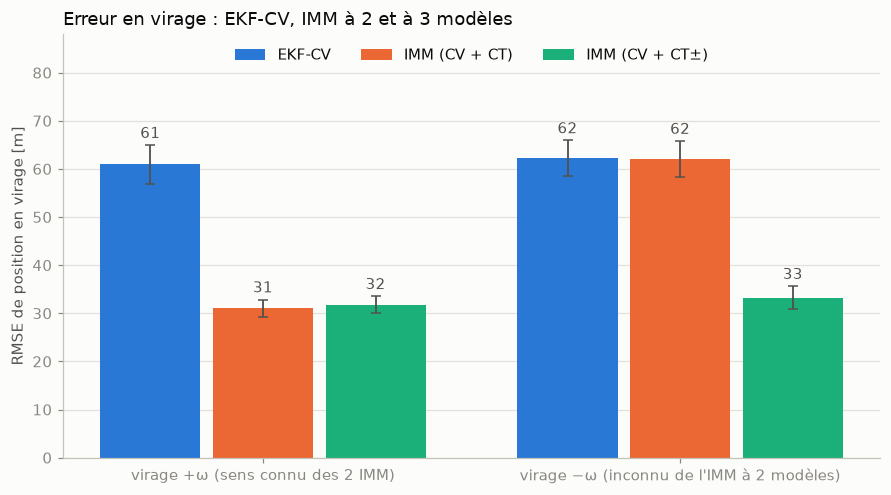

In [8]:
fig, ax = plt.subplots(figsize=(8.2, 4.6))
groups = [("virage +ω (sens connu des 2 IMM)", "rmse_turn_pos"), ("virage −ω (inconnu de l'IMM à 2 modèles)", "rmse_turn_neg")]
width = 0.24
for i, (name, color) in enumerate(zip(NAMES, [BLUE, ORANGE, AQUA])):
    stats = [mean_ci([r[name][key] for r in results["manœuvres"]]) for _, key in groups]
    x = np.arange(len(groups)) + (i - 1) * (width + 0.03)
    ax.bar(x, [m for m, _ in stats], width, color=color, label=name, yerr=[h for _, h in stats],
           error_kw=dict(ecolor=INK2, lw=1.2, capsize=3))
    for xi, (m, h) in zip(x, stats):
        ax.text(xi, m + h + 1.5, f"{m:.0f}", ha="center", color=INK2)
ax.set_xticks(np.arange(len(groups)), [g for g, _ in groups])
ax.set_ylabel("RMSE de position en virage [m]")
ax.set_title("Erreur en virage : EKF-CV, IMM à 2 et à 3 modèles", loc="left", color=INK)
ax.grid(axis="x", visible=False)
ax.set_ylim(0, 88)
ax.legend(loc="upper center", ncol=3)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/C_virage_par_sens.png")
plt.show()

## Temps par mise à jour

Mesuré **en séquentiel** (un seul processus) sur 8 scénarios « manœuvres » distincts, en médiane [min – max]. Le temps compte tout le
balayage (prédiction + gating + association + mise à jour + gestion de pistes) rapporté au nombre de pistes
(provisoires + confirmées) traitées.

In [9]:
timing = {name: [] for name in NAMES}
for seed in range(100, 108):
    sc = generate_scenario(replace(SCENARIOS["manœuvres"], seed=seed))
    for name, factory in trackers(sc.params).items():
        run = run_tracking(TrackManager(factory), sc.detections)
        timing[name].append(1e6 * sum(run.step_times) / sum(run.n_active))

# médiane et min–max : robustes à une perturbation ponctuelle de la machine
print("| pisteur | temps par mise à jour [µs] : médiane [min – max] | rapport à l'EKF-CV |\n|---|---|---|")
base = np.median(timing["EKF-CV"])
for name in NAMES:
    v = timing[name]
    print(f"| {name} | {np.median(v):.0f} [{min(v):.0f} – {max(v):.0f}] | {np.median(v) / base:.1f} × |")

| pisteur | temps par mise à jour [µs] : médiane [min – max] | rapport à l'EKF-CV |
|---|---|---|
| EKF-CV | 455 [431 – 490] | 1.0 × |
| IMM (CV + CT) | 1304 [1292 – 1344] | 2.9 × |
| IMM (CV + CT±) | 1708 [1678 – 1763] | 3.8 × |


## Ce qu'on retient

- **Chaîne complète validée** : le pisteur GNN + M/N tient 10 navires dans ~10 fausses alarmes par balayage, avec
  ≈ 0,5 fausse piste par scénario de 150 balayages. Ce chiffre est le même pour les trois pisteurs : il dépend du
  gating et de la règle M/N, pas du filtre. Le gating de Mahalanobis normalise l'angle (passage de θ = ±π).
- **L'IMM gagne nettement en virage**… à condition que l'un de ses modèles CT ait le **bon sens de virage** :
  l'IMM à 3 modèles (CV, CT+, CT−) réduit l'erreur en virage d'un facteur ≈ 2 dans les deux sens et supprime quasiment
  les changements d'identité ; l'IMM à 2 modèles ne gagne que dans le sens qu'il connaît.
- **Coût** : l'IMM est plus cher en calcul (≈ 2,9 fois l'EKF-CV par mise à jour à 2 modèles, ≈ 3,8 fois à 3 modèles), et
  **en ligne droite il est légèrement moins bon** (RMSE ≈ +6 % dans le tableau « ligne droite », intervalles disjoints) :
  les modèles CT injectent un peu de bruit quand il n'y a pas de virage.
- Le taux de virage des CT (0,02 rad/s) est fixe : les navires tournent à 0,015–0,03 rad/s, et l'IMM s'en accommode.
  Estimer ce taux dans l'état (EKF à 5 états) est la suite naturelle, hors périmètre ici.